# 01 — Exploratory analysis: Swiss hotel demand and the strong franc

**Question:** how much does franc appreciation explain hotel demand in Swiss cantons and resorts?
This notebook only describes the data and ends with 3 hypotheses to test in Sprint 2.

- Data: `data/processed/tourism.duckdb` (built by `python src/load_data.py` then `python src/build_db.py`); SQL views in `sql/`.
- Covid (Mar 2020 – Dec 2021) is shaded wherever there is a time axis.
- Annual comparisons use complete years only; trends use rolling 12-month sums, where every window is checked to be 12 consecutive months.
- Market shares are shares **of the 7 tracked markets**, not of all guests.
- FX = CHF per 1 EUR: a **falling** line means a **stronger** franc.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import (COVID_ROLLING_NOTE, ORIGIN_COLORS, SEGMENT_COLORS, SOURCE_BFS,
                    SOURCE_BFS_SNB, INK_SOFT, add_source, connect, label_line_ends,
                    save, set_style, shade_covid, year_axis)
from features import rolling_12m_sum

set_style()
con = connect()

## Shared data: canton nights per origin, rolling 12 months

In [2]:
nights = con.sql("""
    SELECT date, geo, origin, nights FROM monthly_nights WHERE level = 'canton'
""").df()
nights["date"] = pd.to_datetime(nights["date"])

# A month with a missing canton would give a partial national sum
assert (nights.groupby(["date", "origin"])["geo"].nunique() == 7).all(), "missing canton-month"

by_origin = nights.groupby(["date", "origin"], as_index=False)["nights"].sum()
roll = rolling_12m_sum(by_origin, "nights", ["origin"])

# Base = window ending Dec 2014, i.e. calendar year 2014 (last year before the floor removal)
base = roll.loc[roll["date"] == "2014-12-01"].set_index("origin")["rolling_12m"]
assert len(base) == 7
roll["index_2014"] = 100 * roll["rolling_12m"] / roll["origin"].map(base)
idx = roll.pivot(index="date", columns="origin", values="index_2014")
print(f"{idx.index.min():%b %Y} -> {idx.index.max():%b %Y}, {len(idx)} windows")
idx.iloc[[0, 108, 168, -1]].round(0)

Dec 2005 -> Jul 2026, 248 windows


origin,China,France,Germany,Italy,Switzerland,United Kingdom,United States
date,,,,,,,
2005-12-01,18.0,95.0,128.0,106.0,91.0,124.0,91.0
2014-12-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2019-12-01,145.0,95.0,89.0,88.0,115.0,99.0,156.0
2026-07-01,86.0,113.0,86.0,91.0,138.0,102.0,241.0


## Chart 1 — Canton nights by origin, indexed to 2014 = 100

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/01_canton_nights_index.png')

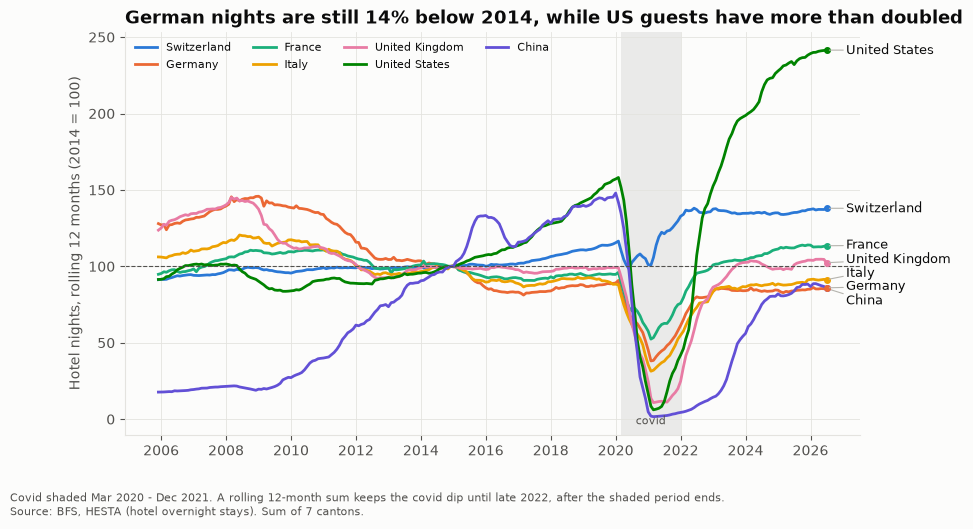

In [3]:
last = idx.iloc[-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
for origin in ORIGIN_COLORS:
    ax.plot(idx.index, idx[origin], color=ORIGIN_COLORS[origin], label=origin)
ax.axhline(100, color=INK_SOFT, lw=0.8, ls="--")
shade_covid(ax)
year_axis(ax)
label_line_ends(ax, {o: (idx.index[-1], last[o]) for o in ORIGIN_COLORS}, ORIGIN_COLORS, min_gap=9)
ax.set_ylabel("Hotel nights, rolling 12 months (2014 = 100)")
assert last["United States"] > 200 and last["Germany"] < 100, "title claim no longer holds"
ax.set_title(f"German nights are still {100 - last['Germany']:.0f}% below 2014, "
             f"while US guests have more than doubled", loc="left")
ax.legend(ncol=4, loc="upper left", fontsize=8)
add_source(fig, SOURCE_BFS + ". Sum of 7 cantons.", COVID_ROLLING_NOTE)
fig.subplots_adjust(bottom=0.16, right=0.86)
save(fig, "01_canton_nights_index")

## Chart 2 — EUR/CHF and German nights, with key franc events

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/02_eurchf_vs_german_nights.png')

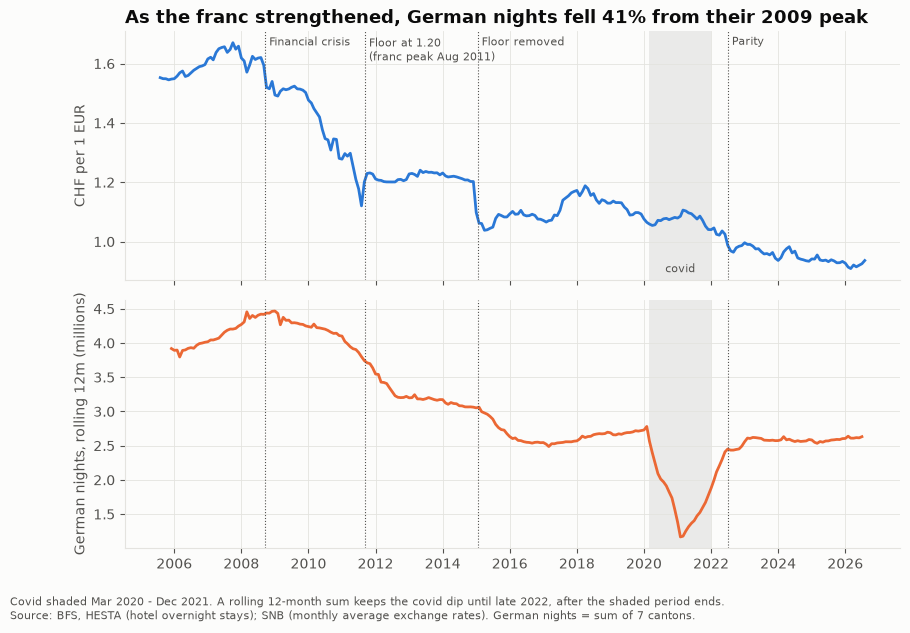

In [4]:
eur = con.sql("SELECT date, chf_per_unit FROM fx WHERE currency = 'EUR' ORDER BY date").df()
eur["date"] = pd.to_datetime(eur["date"])
german = roll.loc[roll["origin"] == "Germany", ["date", "rolling_12m"]]

EVENTS = [  # date, label
    ("2008-09-15", "Financial crisis"),
    ("2011-09-06", "Floor at 1.20\n(franc peak Aug 2011)"),
    ("2015-01-15", "Floor removed"),
    ("2022-07-01", "Parity"),
]
peak = german.loc[german["rolling_12m"].idxmax()]
drop = 100 * (german["rolling_12m"].iloc[-1] / peak["rolling_12m"] - 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.8), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1]})
ax1.plot(eur["date"], eur["chf_per_unit"], color=ORIGIN_COLORS["Switzerland"])
ax1.set_ylabel("CHF per 1 EUR")
ax2.plot(german["date"], german["rolling_12m"] / 1e6, color=ORIGIN_COLORS["Germany"])
ax2.set_ylabel("German nights, rolling 12m (millions)")
for ax in (ax1, ax2):
    shade_covid(ax, label=ax is ax1)
    for d, _ in EVENTS:
        ax.axvline(pd.Timestamp(d), color=INK_SOFT, lw=0.8, ls=":")
for d, text in EVENTS:
    ax1.annotate(text, xy=(pd.Timestamp(d), 0.98), xycoords=("data", "axes fraction"),
                 xytext=(3, 0), textcoords="offset points", ha="left", va="top",
                 fontsize=8, color=INK_SOFT)
year_axis(ax2)
ax1.set_title(f"As the franc strengthened, German nights fell {abs(drop):.0f}% "
              f"from their {peak['date']:%Y} peak", loc="left")
add_source(fig, SOURCE_BFS_SNB + ". German nights = sum of 7 cantons.", COVID_ROLLING_NOTE)
fig.subplots_adjust(bottom=0.12, hspace=0.08)
save(fig, "02_eurchf_vs_german_nights")

## Chart 3 — Year-over-year change in 2015, by origin

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/03_yoy_2015_by_origin.png')

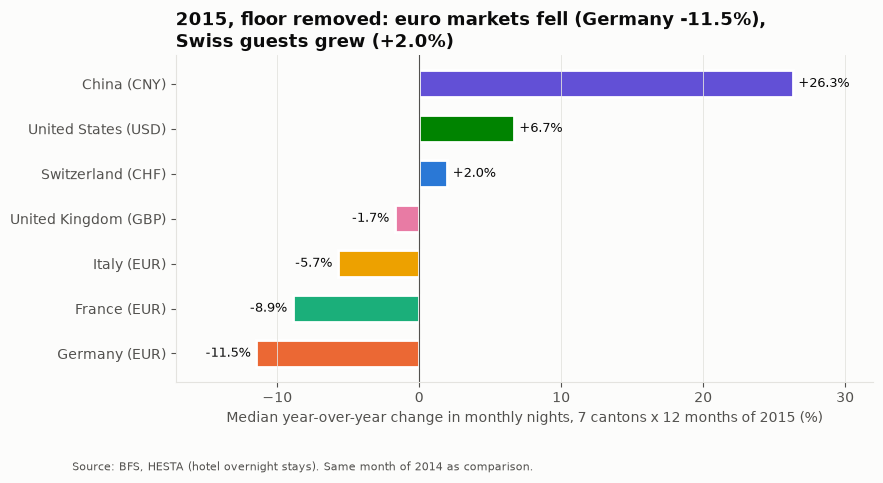

In [5]:
yoy = con.sql("""
    SELECT origin, MEDIAN(yoy_pct) AS median_yoy, COUNT(yoy_pct) AS n
    FROM yoy_change
    WHERE level = 'canton' AND year(date) = 2015
    GROUP BY origin ORDER BY median_yoy
""").df()
assert (yoy["n"] == 7 * 12).all(), "every origin needs 12 months x 7 cantons"
currency = {"Switzerland": "CHF", "Germany": "EUR", "France": "EUR", "Italy": "EUR",
            "United Kingdom": "GBP", "United States": "USD", "China": "CNY"}
de = yoy.set_index("origin").loc["Germany", "median_yoy"]
ch = yoy.set_index("origin").loc["Switzerland", "median_yoy"]

fig, ax = plt.subplots(figsize=(9, 4.8))
labels = [f"{o} ({currency[o]})" for o in yoy["origin"]]
bars = ax.barh(labels, yoy["median_yoy"], color=[ORIGIN_COLORS[o] for o in yoy["origin"]],
               height=0.6, edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{v:+.1f}%" for v in yoy["median_yoy"]], padding=4, fontsize=9)
ax.axvline(0, color=INK_SOFT, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median year-over-year change in monthly nights, 7 cantons x 12 months of 2015 (%)")
ax.set_title(f"2015, floor removed: euro markets fell (Germany {de:+.1f}%),\n"
             f"Swiss guests grew ({ch:+.1f}%)", loc="left")
ax.margins(x=0.15)
add_source(fig, SOURCE_BFS + ". Same month of 2014 as comparison.")
fig.subplots_adjust(bottom=0.2)
save(fig, "03_yoy_2015_by_origin")

## Chart 4 — Market mix by canton, 2019 (last full pre-covid year)

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/04_market_mix_2019.png')

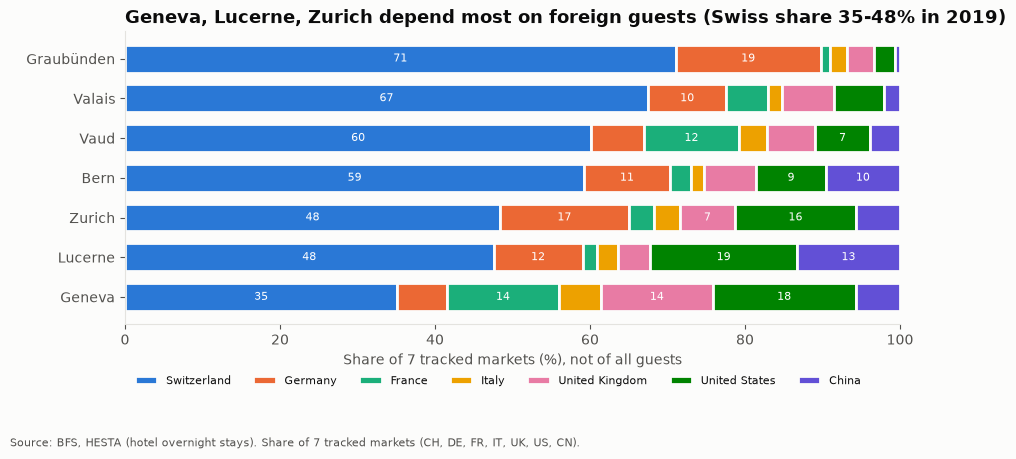

In [6]:
mix = con.sql("""
    SELECT geo, origin, share_of_tracked_pct, n_months
    FROM market_share WHERE level = 'canton' AND year = 2019
""").df()
assert (mix["n_months"] == 12).all(), "2019 must be a complete year"
share = mix.pivot(index="geo", columns="origin", values="share_of_tracked_pct")[list(ORIGIN_COLORS)]
share = share.sort_values("Switzerland")          # most foreign-dependent canton on top
assert np.allclose(share.sum(axis=1), 100)

fig, ax = plt.subplots(figsize=(10, 4.8))
left = np.zeros(len(share))
for origin in ORIGIN_COLORS:
    vals = share[origin].to_numpy()
    ax.barh(share.index, vals, left=left, color=ORIGIN_COLORS[origin], label=origin,
            height=0.7, edgecolor="#fcfcfb", linewidth=2)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 7:
            ax.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white")
    left += vals
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_xlabel("Share of 7 tracked markets (%), not of all guests")
low = share["Switzerland"].nsmallest(3)
ax.set_title(f"{', '.join(low.index)} depend most on foreign guests "
             f"(Swiss share {low.iloc[0]:.0f}-{low.iloc[-1]:.0f}% in 2019)", loc="left")
ax.legend(ncol=7, loc="upper left", bbox_to_anchor=(0, -0.14), fontsize=8)
add_source(fig, SOURCE_BFS + ". Share of 7 tracked markets (CH, DE, FR, IT, UK, US, CN).")
fig.subplots_adjust(bottom=0.27)
save(fig, "04_market_mix_2019")

## Chart 5 — Seasonal profile by canton, coloured by segment

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/05_seasonal_profile.png')

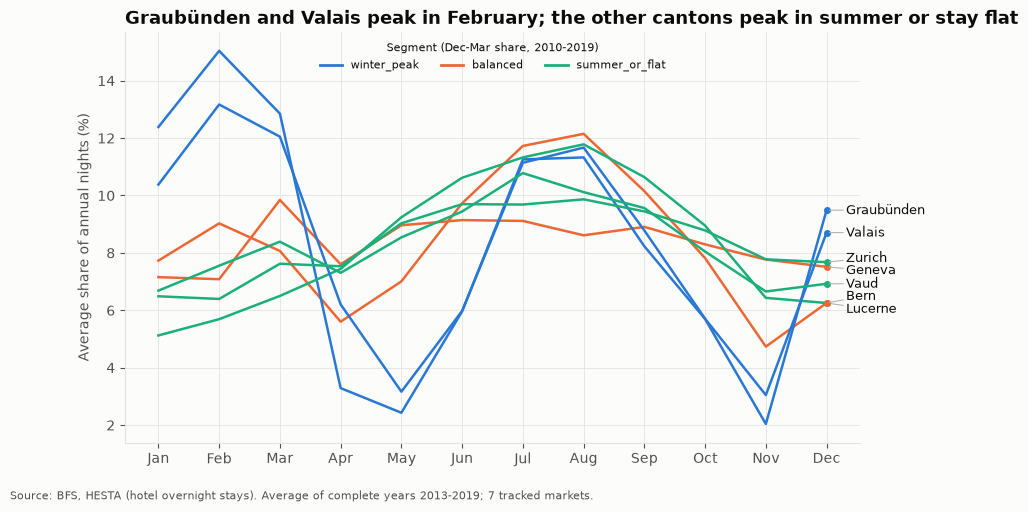

In [7]:
season = con.sql("""
    SELECT p.geo, p.month, p.avg_share_pct, s.segment
    FROM seasonal_profile AS p JOIN canton_segment AS s USING (geo)
    WHERE p.level = 'canton'
""").df()
assert season["geo"].nunique() == 7 and len(season) == 7 * 12
prof = season.pivot(index="month", columns="geo", values="avg_share_pct")
segment = season.drop_duplicates("geo").set_index("geo")["segment"]
colors = {g: SEGMENT_COLORS[s] for g, s in segment.items()}

fig, ax = plt.subplots(figsize=(10, 5.4))
for geo in prof.columns:
    ax.plot(prof.index, prof[geo], color=colors[geo], lw=1.8)
for seg, c in SEGMENT_COLORS.items():
    ax.plot([], [], color=c, label=seg)
label_line_ends(ax, {g: (12, prof.loc[12, g]) for g in prof.columns}, colors, min_gap=0.45)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Average share of annual nights (%)")
ax.set_title("Graubünden and Valais peak in February; the other cantons peak in summer or stay flat",
             loc="left")
ax.legend(title="Segment (Dec-Mar share, 2010-2019)", loc="upper center", ncol=3, fontsize=8,
          title_fontsize=8)
add_source(fig, SOURCE_BFS + ". Average of complete years 2013-2019; 7 tracked markets.")
fig.subplots_adjust(bottom=0.12, right=0.86)
save(fig, "05_seasonal_profile")

## Chart 6 — Average length of stay, Germany vs Switzerland, paired resorts

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/06_length_of_stay_pairs.png')

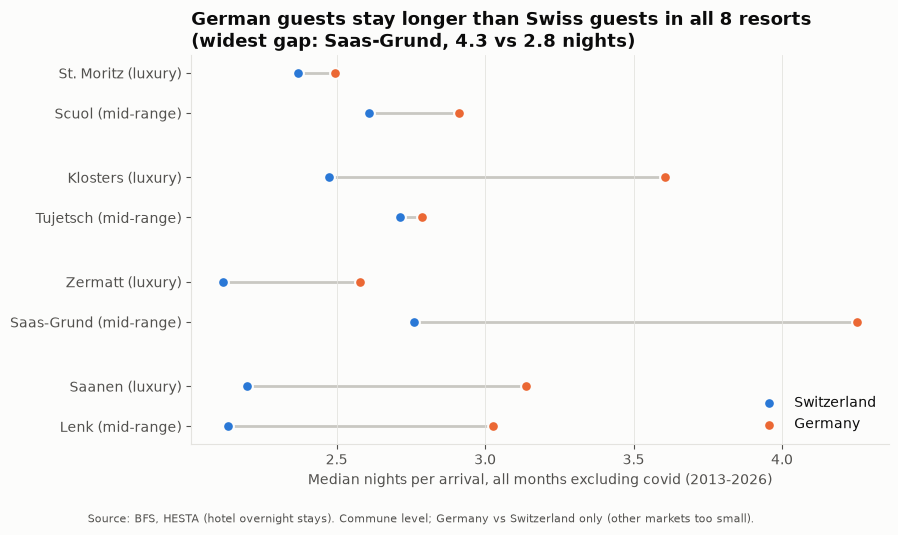

In [8]:
PAIRS = [("St. Moritz", "Scuol"), ("Klosters", "Tujetsch"),
         ("Zermatt", "Saas-Grund"), ("Saanen", "Lenk")]       # (luxury, mid-range)
communes = [c for pair in PAIRS for c in pair]
stay = con.sql(f"""
    SELECT geo, origin, MEDIAN(avg_stay_nights) AS median_stay, COUNT(avg_stay_nights) AS n
    FROM length_of_stay
    WHERE NOT is_covid AND geo IN {tuple(communes)}
    GROUP BY geo, origin
""").df().pivot(index="geo", columns="origin", values="median_stay")
assert len(stay) == 8 and stay.notna().all().all()

ypos, labels, y = [], [], 0
for lux, mid in PAIRS:
    for c, kind in [(lux, "luxury"), (mid, "mid-range")]:
        ypos.append(y); labels.append(f"{c} ({kind})"); y -= 1
    y -= 0.6                                                # gap between pairs
fig, ax = plt.subplots(figsize=(9, 5.4))
for yy, c in zip(ypos, communes):
    ax.plot([stay.loc[c, "Switzerland"], stay.loc[c, "Germany"]], [yy, yy], color="#c9c8c2", lw=2, zorder=1)
for origin in ["Switzerland", "Germany"]:
    ax.scatter(stay.loc[communes, origin], ypos, s=60, color=ORIGIN_COLORS[origin], label=origin,
               zorder=2, edgecolor="#fcfcfb", linewidth=1.5)
ax.set_yticks(ypos, labels)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median nights per arrival, all months excluding covid (2013-2026)")
gap = (stay["Germany"] - stay["Switzerland"]).idxmax()
ax.set_title(f"German guests stay longer than Swiss guests in all 8 resorts\n"
             f"(widest gap: {gap}, {stay.loc[gap, 'Germany']:.1f} vs "
             f"{stay.loc[gap, 'Switzerland']:.1f} nights)", loc="left")
assert (stay["Germany"] > stay["Switzerland"]).all(), "title claim no longer holds"
ax.legend(loc="lower right")
add_source(fig, SOURCE_BFS + ". Commune level; Germany vs Switzerland only (other markets too small).")
fig.subplots_adjust(bottom=0.16)
save(fig, "06_length_of_stay_pairs")

## Hypotheses for Sprint 2

**H1 — Euro-market demand moves with EUR/CHF; domestic demand does not** *(Chart 3)*.
In 2015, the year the floor was removed, the median month of German nights fell 11.5% year on year, French 8.9% and Italian 5.7%, while Swiss nights rose 2.0%. Sprint 2 test: a log-log regression of euro-market nights on lagged EUR/CHF (seasonal controls, covid excluded) should give a **positive** elasticity (a falling CHF-per-EUR rate = stronger franc = fewer nights), close to zero for Swiss guests.

**H2 — The 2015 shock caused a lasting level shift in German demand, not a temporary dip** *(Chart 1)*.
German nights in the 7 cantons are still about 14% below 2014 in mid-2026, while US guests more than doubled and Swiss guests grew by more than a third. Sprint 2 test: in the event study (2014 = 100), check whether German nights return to their pre-2015 trend after 12–24 months, or settle at a lower level.

**H3 — Cantons that rely more on euro guests are more exposed to the franc** *(Chart 4)*.
Germany alone was 18.7% of tracked nights in Graubünden and 16.6% in Zurich in 2019, against about 6–7% in Geneva and Vaud. Sprint 2 test: rank cantons by FX elasticity and compare that ranking with their euro-market share; Graubünden and Zurich should be among the most vulnerable.

*Caveat: Swiss guests are not a clean control group — a strong franc also makes holidays abroad cheaper for them. These comparisons are descriptive, not causal.*

In [9]:
con.close()
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("*.png")))

['01_canton_nights_index.png', '02_eurchf_vs_german_nights.png', '03_yoy_2015_by_origin.png', '04_market_mix_2019.png', '05_seasonal_profile.png', '06_length_of_stay_pairs.png']
